<a href="https://colab.research.google.com/github/JimenaVegaS/Challenge-2--Jimena-Vega/blob/main/pipeline_busqueda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline de razonamiento, búsqueda y resultados

## 1. Definición del problema

El objetivo es seleccionar asteroides candidatos para una posible misión de minería espacial, considerando su potencial estimado de rescursos y las restricciones de la misión.

Para representar el problema, se utilizará un conjunto de candidatos con datos simulados sobre su potencial de recursos, distancia y costo estimado. Mediante un procedimiento de búsqueda, se explorarán las alternativas disponibles, se descartarán las que incumplan las restricciones y se identificará la selección con mejor puntuación entre las alternativas válidas.

Este pipeline utiliza datos sintéticos con fines académicos. Por lo tanto, sus resultados permiten demostrar el funcionamiento del procedimiento, pero no garantizan la viabilidad de una misión espacial real.

## 2. Definición de los datos simulados

In [9]:
asteroides = [
    {
        "nombre": "Asteroide A",
        "potencial_recursos": 80,
        "distancia": 4,
        "costo": 60
    },
    {
        "nombre": "Asteroide B",
        "potencial_recursos": 95,
        "distancia": 8,
        "costo": 90
    },
    {
        "nombre": "Asteroide C",
        "potencial_recursos": 65,
        "distancia": 3,
        "costo": 40,
    },
    {
        "nombre":"Asteroide D",
        "potencial_recursos": 90,
        "distancia": 6,
        "costo": 70
    },
    {
        "nombre": "Asteroide E",
        "potencial_recursos": 55,
        "distancia": 2,
        "costo": 25
    }
]

#Retricciones
presupuesto_maximo = 100
distancia_maxima = 7
max_asteroides = 2

print("Cantidad de canditados:",len(asteroides))
print("Presupuesto maximo:", presupuesto_maximo)
print("Distancia máxima:", distancia_maxima)
print("Máximo de asteroides seleccionados:", max_asteroides)

Cantidad de canditados: 5
Presupuesto maximo: 100
Distancia máxima: 7
Máximo de asteroides seleccionados: 2


## 3. Evaluacion de canditados y restricciones

En esta etapa se evalúa cada asteroide candidato de acuerdo con las restricciones definidas para la misión simulada. Se verifica que su distancia no supere el límite permitido y que su costo individual no exceda el presupuesto máximo.

Los candidatos que cumplen ambas condiciones se consideran viables para continuar con el proceso de búsqueda. Esta evaluación reduce las alternativas que deberán analizarse en las siguientes etapas.

In [3]:
def cumple_restricciones(asteroide):
  return(
      asteroide["distancia"] <= distancia_maxima
      and asteroide["costo"] <= presupuesto_maximo
  )

for asteroide in asteroides:
  if cumple_restricciones(asteroide):
    resultado = "Candidato viable"
  else:
    resultado = "Candidato descartado"

  print(
      asteroide["nombre"],
      "| Distancia:", asteroide["distancia"],
      "| Costo:", asteroide["costo"],
      "| Resultado:", resultado
  )

Asteroide A | Distancia: 4 | Costo: 60 | Resultado: Candidato viable
Asteroide B | Distancia: 8 | Costo: 90 | Resultado: Candidato descartado
Asteroide C | Distancia: 3 | Costo: 40 | Resultado: Candidato viable
Asteroide D | Distancia: 6 | Costo: 70 | Resultado: Candidato viable
Asteroide E | Distancia: 2 | Costo: 25 | Resultado: Candidato viable


## 4. Exploración de combinaciones mediante búsqueda exhaustiva

Se implementa un algoritmo de búsqueda exhaustiva que genera diferentes combinaciones de asteroides candidatos. Cada combinación se evalúa según tres condiciones: el presupuesto total, la distancia máxima permitida para cada candidato y la cantidad máxima de asteroides seleccionados.

Las combinaciones que incumplen alguna restricción se descartan. Entre las combinaciones válidas, se selecciona aquella que maximiza la suma de las puntuaciones simuladas de potencial de recursos.

Esta estrategia permite examinar todas las combinaciones posibles del conjunto de datos y encontrar la mejor solución según el criterio definido. Su principal limitación es que la cantidad de combinaciones crece rápidamente cuando aumenta el número de candidatos.

In [4]:
from itertools import combinations

mejor_seleccion = []
mejor_potencial = -1
combinaciones_evaluadas = 0
combinaciones_validas = 0

for cantidad in range (1 , max_asteroides + 1):
  for combinacion in combinations(asteroides, cantidad):
    combinaciones_evaluadas += 1

    costo_total = sum(a["costo"] for a in combinacion)
    distancia_valida = all(
        a["distancia"] <= distancia_maxima
        for a in combinacion
    )

    if (
        costo_total <= presupuesto_maximo
        and distancia_valida
        and len(combinacion) <= max_asteroides
    ):
      combinaciones_validas += 1

      potencial_total = sum(
          a["potencial_rescursos"] for a in combinacion
      )

      if potencial_total > mejor_potencial:
        mejor_potencial = potencial_total
        mejor_seleccion = list(combinacion)

print("Combinaciones evaluadas:", combinaciones_evaluadas)
print("Combinaciones válidas:", combinaciones_validas)
print("\nMejor selección encontrada:")

for asteroide in mejor_seleccion:
  print("-",asteroide["nombre"])

print("Potencial total:", mejor_potencial)
print("Costo total:", sum(a["costo"] for a in mejor_seleccion))


Combinaciones evaluadas: 15
Combinaciones válidas: 8

Mejor selección encontrada:
- Asteroide A
- Asteroide C
Potencial total: 145
Costo total: 100


## 5. Análisis e interpretación de resultados

El algoritmo de búsqueda exhaustiva evaluó 15 combinaciones posibles de uno o dos asteroides candidatos. De estas alternativas, 8 cumplieron las restricciones de presupuesto, distancia y cantidad máxima de candidatos.

La mejor selección encontrada está conformada por los asteroides A y C, que alcanzan un potencial total simulado de 145 puntos con un costo conjunto de 100 unidades de presupuesto. Esta combinación cumple las restricciones establecidas y obtiene la mayor puntuación entre las alternativas válidas evaluadas.

Los resultados demuestran que seleccionar únicamente el asteroide con mayor potencial individual no garantiza la mejor solución, ya que también deben considerarse los costos y las restricciones de la misión. Sin embargo, las puntuaciones utilizadas son simuladas y no constituyen estimaciones reales de recursos minerales.

## 6. Visualización de resultados

Se utilizará un gráfico de barras para comparar el potencial de recursos simulado de los asteroides candidatos. Los asteroides seleccionados por el algoritmo se distinguirán de los demás, lo que permitirá visualizar su contribución al resultado de la búsqueda.

Esta visualización facilita la interpretación de la selección obtenida y permite comparar el potencial individual de los candidatos. La decisión final depende tanto de estas puntuaciones como de las restricciones de la misión.

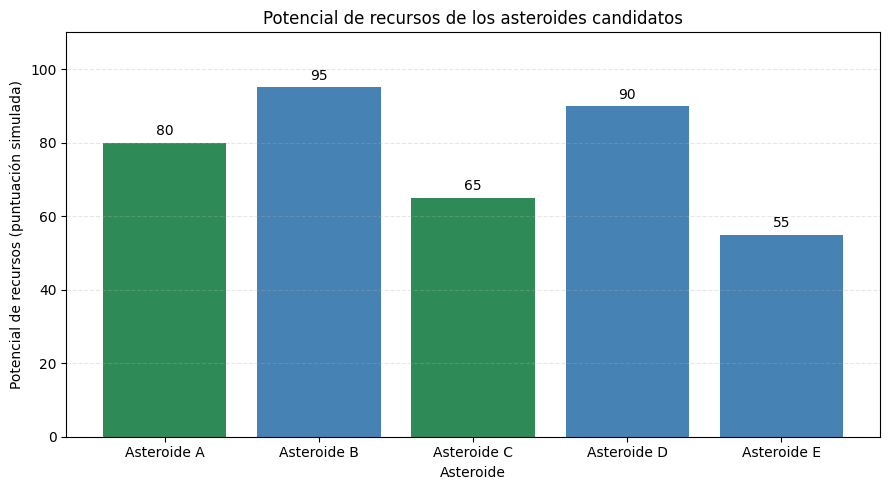

In [10]:

import matplotlib.pyplot as plt

# Identificar los asteroides seleccionados
nombres_seleccionados = {
    a["nombre"] for a in mejor_seleccion
}

nombres = [a["nombre"] for a in asteroides]
potenciales = [a["potencial_recursos"] for a in asteroides]

# Diferenciar candidatos seleccionados y no seleccionados
colores = [
    "seagreen" if nombre in nombres_seleccionados else "steelblue"
    for nombre in nombres
]

plt.figure(figsize=(9, 5))
barras = plt.bar(nombres, potenciales, color=colores)

plt.title("Potencial de recursos de los asteroides candidatos")
plt.xlabel("Asteroide")
plt.ylabel("Potencial de recursos (puntuación simulada)")
plt.ylim(0, 110)
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Mostrar el valor encima de cada barra
for barra, valor in zip(barras, potenciales):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 2,
        str(valor),
        ha="center"
    )

plt.tight_layout()
plt.show()


## Conlusiones

El pipeline de búsqueda permitió evaluar sistemáticamente las combinaciones posibles de asteroides candidatos, aplicando las restricciones de presupuesto, distancia y cantidad máxima de selección.

De las 15 combinaciones evaluadas, 8 cumplieron las condiciones establecidas. La mejor selección encontrada fue la formada por los asteroides A y C, con un potencial total simulado de 145 puntos y un costo conjunto de 100 unidades de presupuesto.

La búsqueda exhaustiva resultó adecuada para este conjunto pequeño de candidatos porque permite comparar todas las alternativas posibles y obtener la mejor solución según el criterio definido. Sin embargo, su costo computacional puede aumentar considerablemente al crecer el número de candidatos.

Los resultados dependen de los datos y las restricciones simuladas. En una aplicación real, sería necesario contar con información validada sobre los asteroides y considerar otros factores técnicos, económicos y operativos.
